# Practical No. 04 — Image Generation using Deep Convolutional GAN (DCGAN)

**Student:** Shraddha Upadhye

**PRN:** 202401110060



## 1. Import libraries and configure reproducibility
We set random seeds so that the dataset sampling and initial model weights are repeatable. The notebook runs on CPU or GPU; this compact model is intentionally designed for quick execution.

In [ ]:
import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits

%matplotlib inline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Keep CPU execution efficient in small notebook environments.
try:
    torch.set_num_threads(min(2, os.cpu_count() or 1))
except Exception:
    pass

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Load and preprocess the dataset
The original Digits data contains 1,797 grayscale images of handwritten digits (0–9), each 8 × 8 pixels with pixel intensities in the range 0–16. We resize each image to 16 × 16, convert it to a one-channel tensor, and normalise the intensity range to **[-1, 1]**. This matches the Generator's final `tanh` activation.

The GAN is unconditional: digit labels are used only to describe and inspect the dataset, not as training targets.

In [ ]:
IMAGE_SIZE = 16
CHANNELS = 1
BATCH_SIZE = 64
EPOCHS = 30
LATENT_DIM = 64

raw_digits = load_digits()
processed_images = []
for source_image in raw_digits.images:
    # Scale the original 0..16 values to uint8, then resize to 16x16.
    uint8_image = (source_image / 16.0 * 255.0).round().astype(np.uint8)
    resized = Image.fromarray(uint8_image).resize(
        (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
    )
    image_array = np.asarray(resized, dtype=np.float32) / 255.0  # [0, 1]
    image_array = image_array[None, :, :]                       # (C, H, W)
    image_array = (image_array - 0.5) / 0.5                     # [-1, 1]
    processed_images.append(image_array)

X = torch.tensor(np.stack(processed_images), dtype=torch.float32)
y = torch.tensor(raw_digits.target, dtype=torch.long)
dataset = TensorDataset(X, y)
train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    pin_memory=(DEVICE.type == 'cuda'),
)

print('Dataset:', 'Scikit-learn Digits')
print('Total images:', len(dataset))
print('Original image shape:', tuple(raw_digits.images.shape[1:]))
print('Training image tensor shape:', tuple(X.shape[1:]))
print('Normalised pixel range:', (round(float(X.min()), 3), round(float(X.max()), 3)))
print('Batch size:', BATCH_SIZE, '| Batches per epoch:', len(train_loader))

Dataset: Scikit-learn Digits
Total images: 1797
Original image shape: (8, 8)
Training image tensor shape: (1, 16, 16)
Normalised pixel range: (-1.0, 1.0)
Batch size: 64 | Batches per epoch: 28


### 2.1 Display real training samples
The following grid confirms that preprocessing has retained the handwritten digit shapes and converted them to the expected grayscale format.

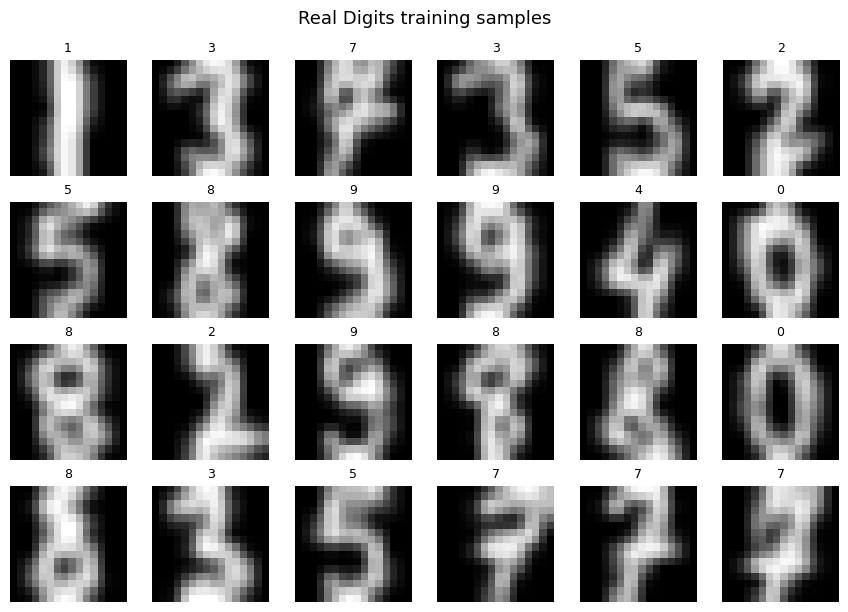

In [ ]:
def display_grid(images, title, ncols=6, save_path=None, labels=None):
    """Display NCHW grayscale images. Inputs are expected in [-1, 1]."""
    if torch.is_tensor(images):
        array = images.detach().cpu().numpy()
    else:
        array = np.asarray(images)
    array = np.clip((array + 1.0) / 2.0, 0.0, 1.0)
    n = len(array)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.45, nrows * 1.55))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i < n:
            ax.imshow(array[i, 0], cmap='gray', vmin=0, vmax=1)
            if labels is not None:
                ax.set_title(str(int(labels[i])), fontsize=9)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(fig)

real_batch, real_labels = next(iter(train_loader))
display_grid(real_batch[:24], 'Real Digits training samples', ncols=6, labels=real_labels[:24])

## 3. Build the DCGAN Generator and Discriminator

**Generator:** takes a random latent vector and uses transposed convolutions to produce a 16 × 16 grayscale image. Batch normalisation and ReLU help the intermediate layers learn; `tanh` gives the required output range of [-1, 1].

**Discriminator:** receives a real or generated image and outputs one raw logit. Strided convolutions learn spatial features without max-pooling. We use `BCEWithLogitsLoss`, so a separate sigmoid layer is not included in the model.

In [ ]:
NGF = 32  # Generator feature width
NDF = 32  # Discriminator feature width

class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, channels=CHANNELS, ngf=NGF):
        super().__init__()
        self.net = nn.Sequential(
            # (N, latent_dim, 1, 1) -> (N, 64, 4, 4)
            nn.ConvTranspose2d(latent_dim, ngf * 2, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(inplace=True),
            # 4x4 -> 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(inplace=True),
            # 8x8 -> 16x16
            nn.ConvTranspose2d(ngf, channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, channels=CHANNELS, ndf=NDF):
        super().__init__()
        self.net = nn.Sequential(
            # 16x16 -> 8x8
            nn.Conv2d(channels, ndf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 8x8 -> 4x4
            nn.Conv2d(ndf, ndf * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # 4x4 -> 1x1 logit
            nn.Conv2d(ndf * 2, 1, kernel_size=4, stride=1, padding=0, bias=False),
        )

    def forward(self, image):
        return self.net(image).view(-1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0.0)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


generator = Generator().to(DEVICE)
discriminator = Discriminator().to(DEVICE)
generator.apply(weights_init)
discriminator.apply(weights_init)

with torch.no_grad():
    test_noise = torch.randn(2, LATENT_DIM, 1, 1, device=DEVICE)
    test_images = generator(test_noise)
    test_logits = discriminator(test_images)

print('Generator output shape:', tuple(test_images.shape))
print('Discriminator output shape:', tuple(test_logits.shape))
print('Generator trainable parameters:', f'{count_parameters(generator):,}')
print('Discriminator trainable parameters:', f'{count_parameters(discriminator):,}')

Generator output shape: (2, 1, 16, 16)
Discriminator output shape: (2,)
Generator trainable parameters: 99,008
Discriminator trainable parameters: 34,432


## 4. Inspect the untrained Generator
Before training, the Generator contains random weights. These initial images are a baseline, not successful generated digits. Later we compare them with the trained outputs.

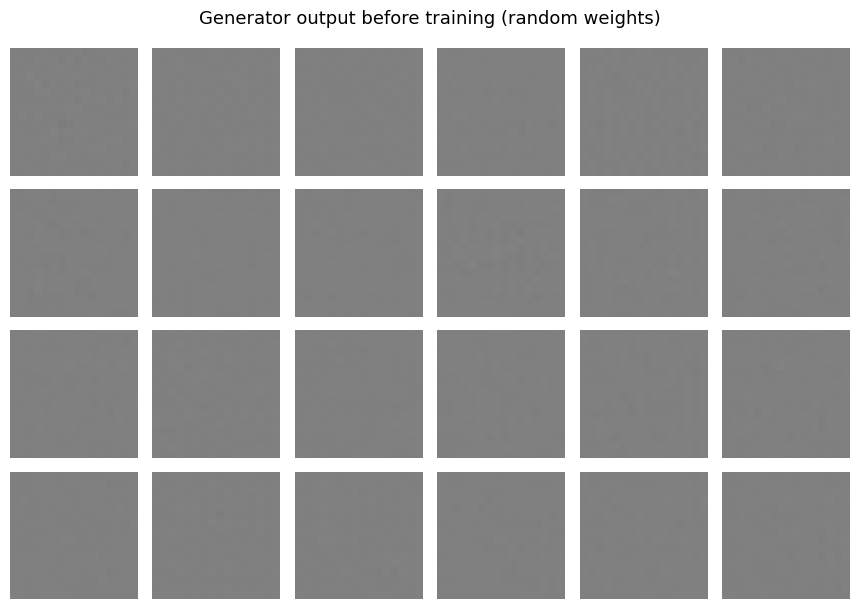

In [ ]:
fixed_noise = torch.randn(24, LATENT_DIM, 1, 1, device=DEVICE)
generator.eval()
with torch.no_grad():
    initial_images = generator(fixed_noise).cpu()
display_grid(initial_images, 'Generator output before training (random weights)', ncols=6)

## 5. Configure adversarial training
Each mini-batch has two phases:

1. **Discriminator update:** classify real images as real and detached generated images as fake.
2. **Generator update:** freeze Discriminator parameters and update the Generator so generated images receive the real target.

We use binary cross-entropy with logits, Adam optimisers, and slightly lower learning rate for the Discriminator to reduce the risk that it learns much faster than the Generator. GAN losses are competitive and need not decrease monotonically.

In [ ]:
LEARNING_RATE_G = 0.0002
LEARNING_RATE_D = 0.00005
BETA1 = 0.5
criterion = nn.BCEWithLogitsLoss()
g_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE_G, betas=(BETA1, 0.999))
d_optimizer = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE_D, betas=(BETA1, 0.999))

history = {'d_loss': [], 'g_loss': [], 'acc_real': [], 'acc_fake': []}
checkpoint_epochs = {1, 5, 15, EPOCHS}
progress_samples = {}
OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'Epochs: {EPOCHS}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Generator learning rate: {LEARNING_RATE_G}')
print(f'Discriminator learning rate: {LEARNING_RATE_D}')
print(f'Optimizer: Adam (beta1={BETA1}, beta2=0.999)')
print('Loss: BCEWithLogitsLoss')

Epochs: 30
Batch size: 64
Generator learning rate: 0.0002
Discriminator learning rate: 5e-05
Optimizer: Adam (beta1=0.5, beta2=0.999)
Loss: BCEWithLogitsLoss


## 6. Train the DCGAN
The notebook records per-epoch losses and the Discriminator's classification accuracy on real and generated samples. The same fixed noise vectors are saved at checkpoints so changes in the generated images can be compared across epochs.

In [ ]:
def train_dcgan(epochs=EPOCHS):
    start_time = time.time()
    fixed_checkpoint_noise = torch.randn(24, LATENT_DIM, 1, 1, device=DEVICE)

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()
        d_losses, g_losses, real_correct, fake_correct = [], [], [], []

        for real_images, _ in train_loader:
            real_images = real_images.to(DEVICE, non_blocking=(DEVICE.type == 'cuda'))
            batch_size = real_images.size(0)
            real_targets = torch.full((batch_size,), 0.9, device=DEVICE)  # mild label smoothing
            fake_targets = torch.zeros(batch_size, device=DEVICE)

            # -- Step A: update Discriminator --
            d_optimizer.zero_grad(set_to_none=True)
            real_logits = discriminator(real_images)
            d_loss_real = criterion(real_logits, real_targets)

            noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
            fake_images = generator(noise).detach()
            fake_logits = discriminator(fake_images)
            d_loss_fake = criterion(fake_logits, fake_targets)
            d_loss = (d_loss_real + d_loss_fake) / 2.0
            d_loss.backward()
            d_optimizer.step()

            real_correct.append((torch.sigmoid(real_logits.detach()) >= 0.5).float().mean().item())
            fake_correct.append((torch.sigmoid(fake_logits.detach()) < 0.5).float().mean().item())

            # -- Step B: update Generator --
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)
            g_optimizer.zero_grad(set_to_none=True)
            generated_for_g = generator(torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE))
            generator_targets = torch.ones(batch_size, device=DEVICE)
            g_loss = criterion(discriminator(generated_for_g), generator_targets)
            g_loss.backward()
            g_optimizer.step()
            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)

            d_losses.append(float(d_loss.item()))
            g_losses.append(float(g_loss.item()))

        history['d_loss'].append(float(np.mean(d_losses)))
        history['g_loss'].append(float(np.mean(g_losses)))
        history['acc_real'].append(float(np.mean(real_correct)))
        history['acc_fake'].append(float(np.mean(fake_correct)))

        if epoch in checkpoint_epochs:
            generator.eval()
            with torch.no_grad():
                progress_samples[epoch] = generator(fixed_checkpoint_noise).cpu().clone()
            generator.train()

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"D loss: {history['d_loss'][-1]:.3f} | "
            f"G loss: {history['g_loss'][-1]:.3f} | "
            f"D acc real: {history['acc_real'][-1]*100:.1f}% | "
            f"D acc fake: {history['acc_fake'][-1]*100:.1f}%"
        )

    total_seconds = time.time() - start_time
    print(f'\nTraining finished in {total_seconds:.1f} seconds on {DEVICE}.')
    return total_seconds

training_seconds = train_dcgan(EPOCHS)

Epoch 01/30 | D loss: 0.714 | G loss: 0.544 | D acc real: 91.6% | D acc fake: 7.1%
Epoch 02/30 | D loss: 0.659 | G loss: 0.549 | D acc real: 100.0% | D acc fake: 2.2%
Epoch 03/30 | D loss: 0.648 | G loss: 0.605 | D acc real: 98.2% | D acc fake: 11.9%
Epoch 04/30 | D loss: 0.624 | G loss: 0.686 | D acc real: 94.5% | D acc fake: 32.8%
Epoch 05/30 | D loss: 0.634 | G loss: 0.695 | D acc real: 91.0% | D acc fake: 40.8%
Epoch 06/30 | D loss: 0.624 | G loss: 0.768 | D acc real: 80.6% | D acc fake: 73.0%
Epoch 07/30 | D loss: 0.614 | G loss: 0.816 | D acc real: 79.2% | D acc fake: 89.2%
Epoch 08/30 | D loss: 0.613 | G loss: 0.833 | D acc real: 77.5% | D acc fake: 86.8%
Epoch 09/30 | D loss: 0.628 | G loss: 0.813 | D acc real: 69.9% | D acc fake: 85.7%
Epoch 10/30 | D loss: 0.628 | G loss: 0.831 | D acc real: 60.2% | D acc fake: 94.0%
Epoch 11/30 | D loss: 0.632 | G loss: 0.846 | D acc real: 54.1% | D acc fake: 94.8%
Epoch 12/30 | D loss: 0.638 | G loss: 0.848 | D acc real: 47.8% | D acc fake:

### 6.1 Visualise training progress
The same noise inputs are used for each checkpoint. Improvements can be assessed by comparing whether random noise gradually develops into digit-like strokes. A short run may still produce soft or imperfect shapes.

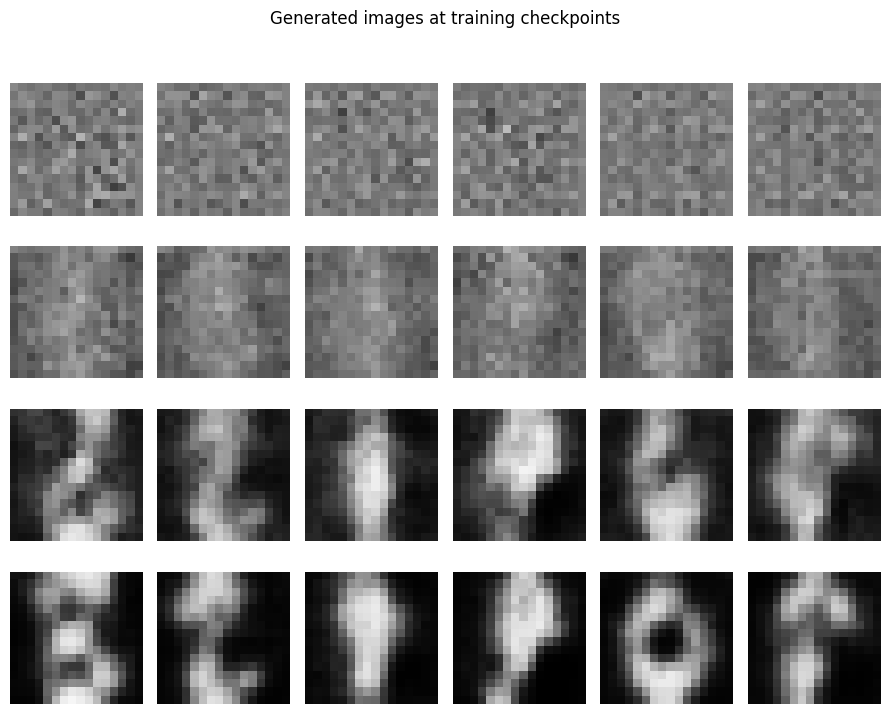

In [ ]:
checkpoint_list = sorted(progress_samples)
fig, axes = plt.subplots(len(checkpoint_list), 6, figsize=(9, 1.8 * len(checkpoint_list)))
axes = np.array(axes).reshape(len(checkpoint_list), 6)
for row, epoch in enumerate(checkpoint_list):
    arr = ((progress_samples[epoch].numpy() + 1) / 2).clip(0, 1)
    for col, ax in enumerate(axes[row]):
        ax.imshow(arr[col, 0], cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
    axes[row, 0].set_ylabel(f'Epoch {epoch}', rotation=0, labelpad=35, va='center')
fig.suptitle('Generated images at training checkpoints', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'training_progress.png'), dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)

## 7. Evaluate training
### 7.1 Generator and Discriminator loss curves
The curves show how the two networks compete. A GAN is not expected to have smoothly decreasing losses. A very strong Discriminator can cause Generator loss to rise; conversely, a weak Discriminator may not provide useful feedback. Interpret the plot together with the generated samples and accuracy.

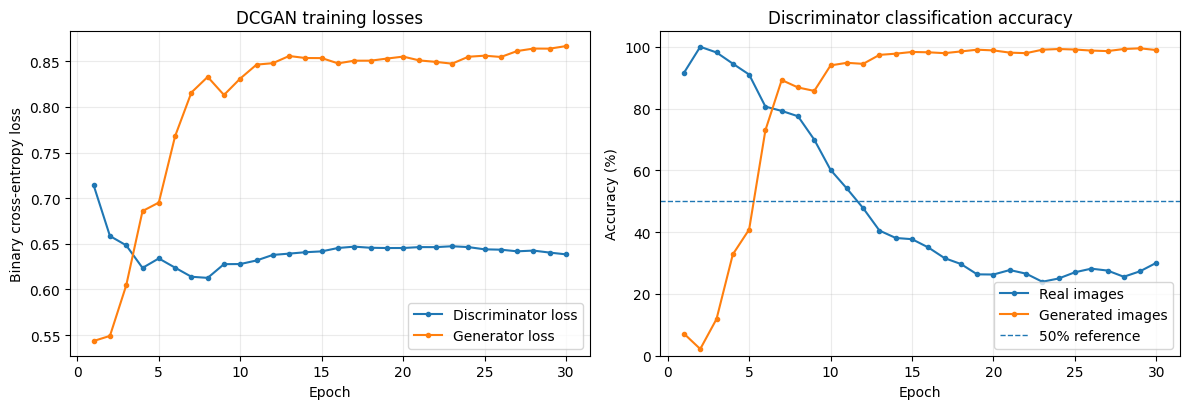

In [ ]:
epoch_axis = np.arange(1, len(history['d_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(epoch_axis, history['d_loss'], marker='o', ms=3, label='Discriminator loss')
axes[0].plot(epoch_axis, history['g_loss'], marker='o', ms=3, label='Generator loss')
axes[0].set_title('DCGAN training losses')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary cross-entropy loss')
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].plot(epoch_axis, np.array(history['acc_real']) * 100, marker='o', ms=3, label='Real images')
axes[1].plot(epoch_axis, np.array(history['acc_fake']) * 100, marker='o', ms=3, label='Generated images')
axes[1].axhline(50, linestyle='--', linewidth=1, label='50% reference')
axes[1].set_title('Discriminator classification accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'loss_and_accuracy_curves.png'), dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)

### 7.2 Final synthetic image grid
The following images are produced by the trained Generator from new random latent vectors. Inspect legibility and variety rather than expecting every image to be a perfect handwritten digit.

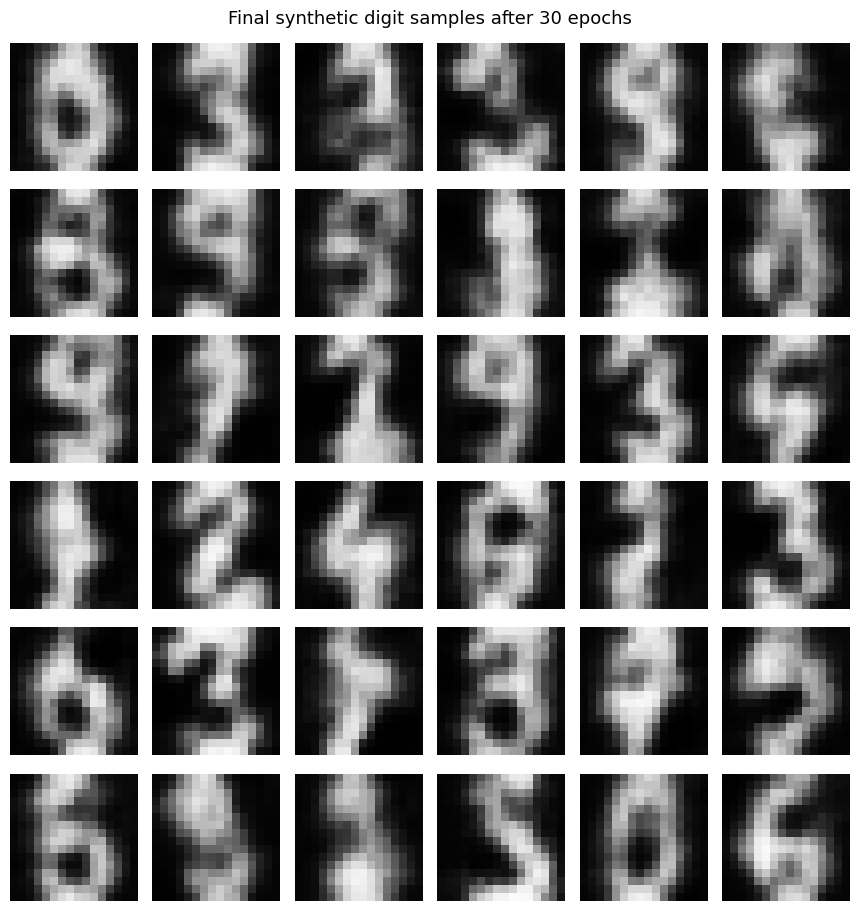

In [ ]:
generator.eval()
with torch.no_grad():
    final_noise = torch.randn(36, LATENT_DIM, 1, 1, device=DEVICE)
    final_images = generator(final_noise).cpu()
display_grid(final_images, f'Final synthetic digit samples after {EPOCHS} epochs', ncols=6,
             save_path=os.path.join(OUTPUT_DIR, 'final_generated_digits.png'))

### 7.3 Real-versus-generated comparison
This is a qualitative check of image structure. Real images contain crisp strokes; generated images may be softer or malformed because the dataset is low resolution and the training run is intentionally compact.

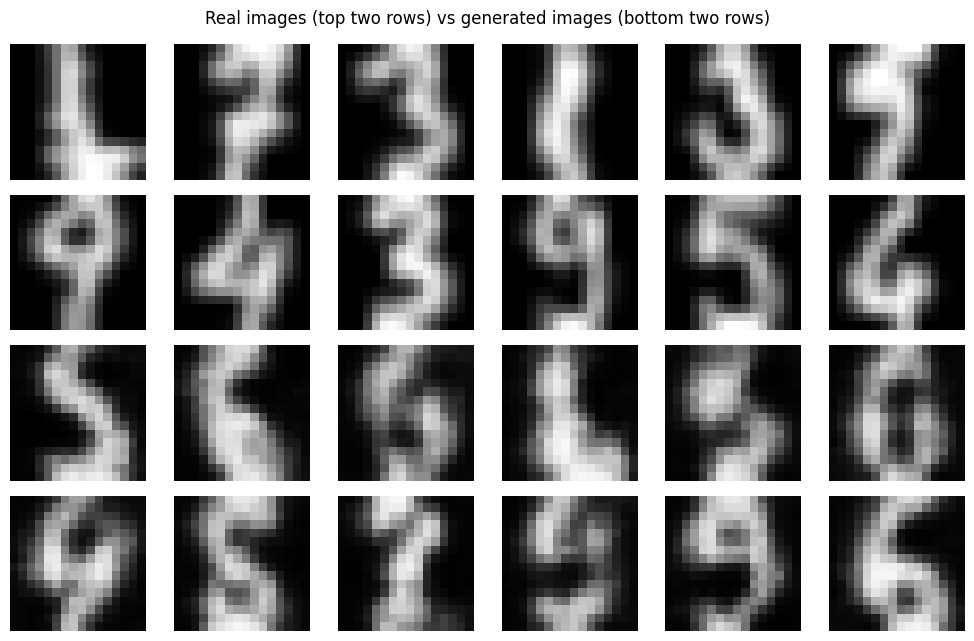

In [ ]:
real_compare, _ = next(iter(train_loader))
with torch.no_grad():
    fake_compare = generator(torch.randn(12, LATENT_DIM, 1, 1, device=DEVICE)).cpu()
real_compare = real_compare[:12].cpu()
fig, axes = plt.subplots(4, 6, figsize=(10, 6.5))
for i in range(12):
    axes[i // 6, i % 6].imshow(((real_compare[i, 0].numpy() + 1) / 2).clip(0, 1), cmap='gray', vmin=0, vmax=1)
    axes[i // 6, i % 6].axis('off')
for i in range(12):
    axes[2 + i // 6, i % 6].imshow(((fake_compare[i, 0].numpy() + 1) / 2).clip(0, 1), cmap='gray', vmin=0, vmax=1)
    axes[2 + i // 6, i % 6].axis('off')
axes[0, 0].set_ylabel('Real', rotation=0, labelpad=28, va='center')
axes[2, 0].set_ylabel('Generated', rotation=0, labelpad=42, va='center')
fig.suptitle('Real images (top two rows) vs generated images (bottom two rows)')
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'real_vs_generated.png'), dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)

### 7.4 Latent-space interpolation
We linearly interpolate between two random latent vectors. The Generator maps each intermediate vector to an image; gradual changes indicate that nearby latent inputs can produce changing visual patterns. This is a qualitative demonstration, not a numerical quality metric.

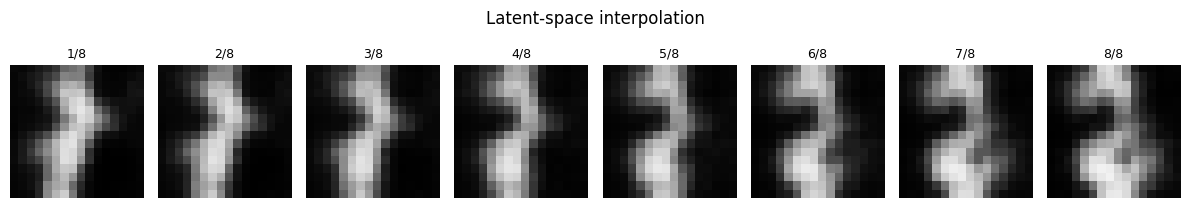

In [ ]:
steps = 8
z_start = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)
z_end = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)
ratios = torch.linspace(0, 1, steps, device=DEVICE).view(-1, 1, 1, 1)
interpolated_z = (1 - ratios) * z_start + ratios * z_end
with torch.no_grad():
    interpolated_images = generator(interpolated_z).cpu()
arr = ((interpolated_images.numpy() + 1) / 2).clip(0, 1)
fig, axes = plt.subplots(1, steps, figsize=(steps * 1.5, 2.2))
for idx, ax in enumerate(axes):
    ax.imshow(arr[idx, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{idx+1}/{steps}', fontsize=9)
    ax.axis('off')
fig.suptitle('Latent-space interpolation')
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'latent_interpolation.png'), dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)

## 8. Results and discussion
Use the actual metrics printed below and refer to the saved image grids when explaining the run. GAN losses are competitive, so neither loss is expected to decrease monotonically. Image quality and diversity must also be judged visually.

In [ ]:
print('DATASET USED: Scikit-learn Digits')
print('Images available:', len(dataset))
print('Image tensor shape:', tuple(X.shape[1:]))
print('Epochs completed:', len(history['d_loss']))
print(f"Final Discriminator loss: {history['d_loss'][-1]:.4f}")
print(f"Final Generator loss:     {history['g_loss'][-1]:.4f}")
print(f"Final Discriminator accuracy on real images: {history['acc_real'][-1]*100:.1f}%")
print(f"Final Discriminator accuracy on generated images: {history['acc_fake'][-1]*100:.1f}%")
print(f'Training time: {training_seconds:.1f} seconds')
print('Generated batch shape:', tuple(final_images.shape))

# Save trained parameters so they can be reused without training again.
torch.save(generator.state_dict(), os.path.join(OUTPUT_DIR, 'dcgan_digits_generator.pth'))
torch.save(discriminator.state_dict(), os.path.join(OUTPUT_DIR, 'dcgan_digits_discriminator.pth'))
print('Saved Generator and Discriminator weights in:', OUTPUT_DIR)

DATASET USED: Scikit-learn Digits
Images available: 1797
Image tensor shape: (1, 16, 16)
Epochs completed: 30
Final Discriminator loss: 0.6385
Final Generator loss:     0.8666
Final Discriminator accuracy on real images: 30.1%
Final Discriminator accuracy on generated images: 98.9%
Training time: 5.5 seconds
Generated batch shape: (36, 1, 16, 16)
Saved Generator and Discriminator weights in: outputs


### Interpretation of results

- **Preprocessing:** all 1,797 grayscale examples were resized to 16 × 16 and normalised to [-1, 1], matching the Generator's `tanh` output.
- **Architecture:** the Generator upsamples a 64-dimensional latent vector to a 16 × 16 image. The Discriminator downsamples an image and outputs one real/fake logit.
- **Training:** the Discriminator and Generator were updated alternately with separate Adam optimizers and `BCEWithLogitsLoss`.
- **Image quality and diversity:** use the final sample grid and real-versus-generated comparison above. The generated strokes may be blurry and some outputs may resemble one another; a small grid can suggest possible repetition but cannot conclusively prove mode collapse.
- **Loss and accuracy:** interpret the plotted curves together. A high Discriminator accuracy on generated samples alone does not prove the Generator is good; visual inspection is also necessary.
- **Limitations:** the source data contains only 8 × 8 digit images, the model is small, and the training duration is limited. Higher-resolution, more realistic generation requires more data, compute, and tuning.

## 9. Conclusion
A compact DCGAN was implemented and trained on the standard Scikit-learn Digits benchmark. The preprocessing pipeline, Generator, Discriminator, adversarial training loop, loss/accuracy plots, generated image grid, real-versus-generated comparison, and latent-space interpolation were completed. The experiment demonstrates how a DCGAN learns to map random latent vectors to digit-like images, while also showing the limitations of a small low-resolution dataset and short training run.

